# What do the intervention's features mean?

The intervention showed that editing some SAE features changes the Solver's adoption decision a little
more than random edits do (`full_study_results.ipynb`). This notebook asks **what those features are**:
do they track *adoption* (deferring to the Critic), or something shallower?

Everything here is read from one run of `scripts/intervention/interpretation/interpret_features.py`, which
looked at each selected feature (10 adoption + 10 retention per representation) four ways:

| | Question | Evidence |
|---|---|---|
| 1 | How often does it fire, in adoption vs retention episodes? | 25,556 train episodes |
| 2 | Which episode properties does it track? | correlations on the same episodes, with the other properties held fixed |
| 3 | What does pushing it make the model say? | logit lens on Gemma's weights |
| 4 | What concept does Claude see in it, and does that description predict new episodes? | Claude describes 30 train episodes, then is tested on 20 validation episodes |

> The figures and tables recompute for any run set below. The written takeaways describe run
> `20261106T221912476834Z`; reread them if you point the notebook at another run. This notebook never
> calls Claude: it only reads the script's saved answers.

## Choose the runs

`RUN_DIR` is the interpretation run. `INTERVENTION_RUN_DIR` is the intervention run whose steering results
section 7 compares against.

In [1]:
RUN_DIR = "results/feature_interpretation_layer25/20261106T221912476834Z"
INTERVENTION_RUN_DIR = "results/intervention_layer25/20261106T000808809026Z-02871d677287"

In [2]:
import json
import os
from pathlib import Path

# Find the repo root so the notebook works from notebooks/intervention/.
ROOT = Path.cwd()
while not (ROOT / "configs" / "intervention").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("Run this notebook from inside the repository.")
    ROOT = ROOT.parent
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import Markdown, display

RUN_DIR = Path(RUN_DIR)
FIGURE_DIR = RUN_DIR / "figures"
for required in ["feature_summary.csv", "concept_profiles.csv", "logit_lens.csv", "run.json"]:
    if not (RUN_DIR / required).is_file():
        raise FileNotFoundError(f"{RUN_DIR / required} not found: run interpret_features.py first.")
FIGURE_DIR.mkdir(exist_ok=True)

## Load the script's output

In [3]:
summary = pd.read_csv(RUN_DIR / "feature_summary.csv")
profiles = pd.read_csv(RUN_DIR / "concept_profiles.csv")
logit_lens = pd.read_csv(RUN_DIR / "logit_lens.csv")
run_settings = json.loads((RUN_DIR / "run.json").read_text())
has_claude = "claude_description" in summary.columns
examples = pd.read_csv(RUN_DIR / "example_episodes.csv") if has_claude else None

# The Fine-tuned decoder shares the Pretrained SAE's encoder, so its features and their values are
# identical: only its logit lens differs. Show it once, where it isn't a duplicate.
REPRESENTATIONS = [name for name in ["L1 SAE", "Pretrained SAE", "Fully fine-tuned", "Raw activations"]
                   if name in set(summary.representation)]
SAES = [name for name in REPRESENTATIONS if name != "Raw activations"]

print(f"{len(summary)} features from {summary.representation.nunique()} representations; "
      f"Claude descriptions: {'yes' if has_claude else 'no'}")
print(f"Profiles on the {run_settings['describe_partition']} partition; "
      f"descriptions tested on {run_settings['test_partition']}.")

100 features from 5 representations; Claude descriptions: yes
Profiles on the train partition; descriptions tested on validation.


### Shared style and names

Same palette as the results notebook: each representation keeps its color. Property names get plain
labels for the figures.

In [4]:
COLOR = {"L1 SAE": "#2a78d6", "Pretrained SAE": "#eb6834", "Fine-tuned decoder": "#1baf7a",
         "Fully fine-tuned": "#8f5ccf", "Raw activations": "#3d3c39"}
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "font.size": 10,
    "svg.fonttype": "none",  # keep SVG text editable
})

PROPERTY_LABELS = {
    "adopted": "Solver adopted (the decision)",
    "critic_answer_is_refusal": "Critic says it can't be answered",
    "a1_is_refusal": "Solver's A1 says it can't be answered",
    "critic_is_correct": "Critic is correct",
    "a1_is_correct": "Solver's A1 is correct",
    "critic_answer_is_date": "Critic's answer is a date",
    "a1_is_date": "A1 is a date",
    "critic_answer_is_number": "Critic's answer is a number",
    "a1_is_number": "A1 is a number",
    "critic_listed_first": "Critic listed as candidate A",
    "number_of_hops": "Number of hops",
    "is_synthetic": "Synthetic (fictional) question",
}
PROPERTY_ORDER = list(PROPERTY_LABELS)            # the decision first, then the Critic's refusal, then shortcuts


def save_figure(fig, file_stem: str) -> None:
    path = FIGURE_DIR / f"{file_stem}.svg"
    fig.savefig(path, format="svg", bbox_inches="tight")
    print(f"Saved {path}")


def feature_label(row) -> str:
    return f"#{row.feature} ({row.feature_set[:3]}.)"

## 1. Overview: every feature in one table

One row per feature. **Fires in %**: share of train episodes where the feature is above zero (for raw
neurons, above the neuron's mean, so it says little). **Strongest property**: the episode property with the
largest coefficient when all properties are fitted together (section 2). **Test score**: how well Claude's
description predicts the feature on 20 held-out episodes (Spearman; 1 is perfect, 0 is chance).

In [5]:
overview_columns = ["representation", "feature", "feature_set", "fires_in_pct_of_episodes", "strongest_property",
                    "top_promoted_tokens"]
if has_claude:
    overview_columns += ["description_test_spearman", "claude_description"]
overview = (summary[summary.representation.isin(REPRESENTATIONS)][overview_columns]
            .assign(strongest_property=lambda table: table.strongest_property.map(PROPERTY_LABELS)))
with pd.option_context("display.max_colwidth", 160, "display.max_rows", 200):
    display(overview.round(2))

,representation,feature,feature_set,fires_in_pct_of_episodes,strongest_property,top_promoted_tokens,description_test_spearman,claude_description
0,Raw activations,321,adoption,50.54,A1 is a date,'czes' 'ාවක්' ' तुम्' 'ixas' 'ੱ',0.41,"The feature activates when the Critic's answer is semantically similar to or a more specific/reformatted version of the Solver's answer, rather than a funda..."
1,Raw activations,653,adoption,49.20,Critic's answer is a date,' pop' ' Holi' ' தெரிய' 'षि' '永久',0.38,The feature activates most strongly when the Solver's answer and the Critic's answer are nearly identical with only minor differences like spelling variatio...
2,Raw activations,1236,adoption,52.74,Critic is correct,'డానికి' ' બા' 'ResultSet' 'Take' ' जानकारियां',-0.12,"The feature activates when the Solver retains its original answer despite the Critic's alternative, suggesting it tracks the Solver's confidence in or commi..."
3,Raw activations,402,adoption,51.87,Critic's answer is a date,'asInstanceOf' ' lingk' ' attain' 'ต์' ' tytu',0.22,"The feature activates strongly when the question involves real historical facts and the Critic provides a concrete, verifiable correction (especially dates)..."
4,Raw activations,841,adoption,51.54,Critic says it can't be answered,' há' ' Erinner' ' നിർ' ' विक्रे' ' á',-0.05,"The feature activates strongly when the question involves entirely fictional entities and the Solver adopts the Critic's specific alternative answer, rather..."
5,Raw activations,1551,adoption,49.35,Critic says it can't be answered,' bloating' ' kvůli' ' обслуживание' 'बीसी' ' itd',0.66,"The feature activates when the question specifically asks about a city (typically 'In which city...' or 'In what city...'), as opposed to questions about pr..."
6,Raw activations,233,adoption,48.18,Critic says it can't be answered,'condensation' 'Holding' ' holding' 'plastic' ' Holding',-0.05,The feature activates most strongly when the Solver adopts a Critic's answer that refines or slightly modifies the Solver's original answer (adding specific...
7,Raw activations,1422,adoption,43.83,Critic's answer is a date,' অবস্থ' '釭' ' chodzi' ' slowdown' ' retiring',0.28,"The feature activates when the Critic's answer differs from the Solver's first answer only by minor spelling variations (one or two characters), as opposed ..."
8,Raw activations,392,adoption,47.97,Critic says it can't be answered,'/' ' relatable' ' envisions' ' иных' ' envision',0.48,"The feature activates most strongly when the Critic provides long, elaborate, multi-clause answers with contextual explanations, regardless of whether the S..."
9,Raw activations,302,adoption,53.41,Critic's answer is a date,' talent' ' Talent' 'talent' ' зуб' ' linn',0.06,"The feature activates strongly when the Solver retains its original answer about Norwegian or Scandinavian locations/topics, and is weak when the Solver ado..."


## 2. ⭐ What do the features track?

Each cell is the feature's coefficient for one property, with **all properties fitted together**, so a
property that only looks related because it overlaps with another shrinks. Red: the feature is higher when
the property holds; blue: lower. Rows are grouped into the adoption set (top) and retention set (bottom).
If the features tracked the decision itself, the first column would light up.

Saved results/feature_interpretation_layer25/20261106T221912476834Z/figures/section02_concept_profile_heatmap_per_feature_by_episode_property.svg


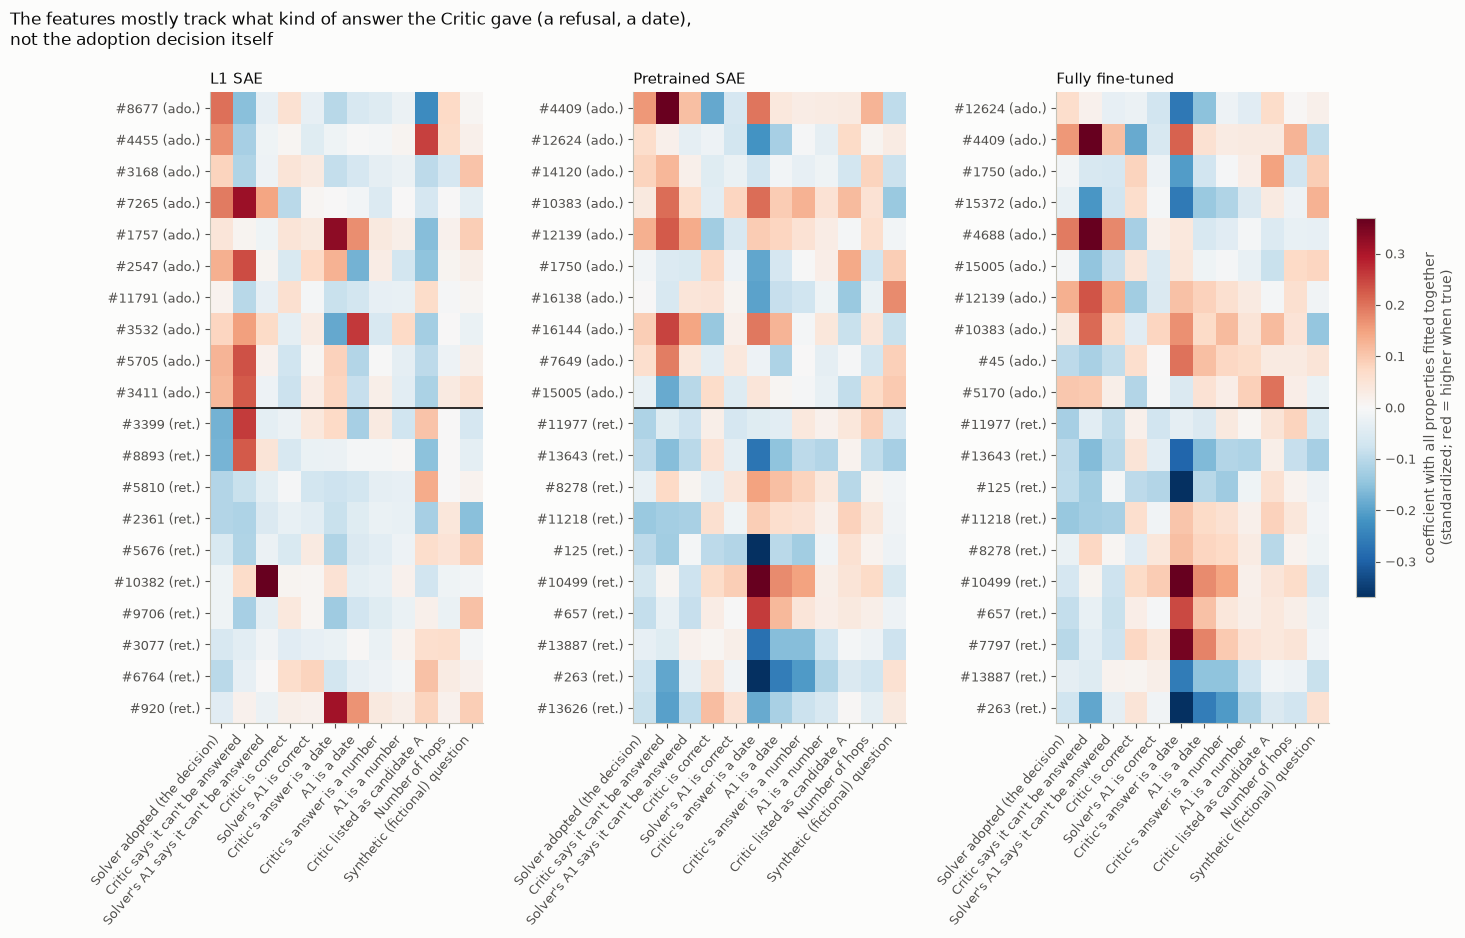

In [6]:
def concept_heatmap(ax, representation: str, color_limit: float):
    rows = summary[summary.representation == representation]
    matrix = (profiles[profiles.representation == representation]
              .pivot(index="feature", columns="property", values="together_coefficient")
              .loc[rows.feature, PROPERTY_ORDER])
    image = ax.imshow(matrix.to_numpy(), cmap="RdBu_r", vmin=-color_limit, vmax=color_limit, aspect="auto")
    ax.set_xticks(range(len(PROPERTY_ORDER)), [PROPERTY_LABELS[p] for p in PROPERTY_ORDER], rotation=50,
                  ha="right")
    ax.set_yticks(range(len(rows)), [feature_label(row) for row in rows.itertuples()])
    n_adoption = int((rows.feature_set == "adoption").sum())
    ax.axhline(n_adoption - 0.5, color=INK, linewidth=1.2)        # adoption set above, retention below
    ax.grid(False)
    ax.set_title(representation, loc="left")
    return image


color_limit = float(profiles.together_coefficient.abs().quantile(0.99))
fig, axes = plt.subplots(1, len(SAES), figsize=(5.8 * len(SAES), 8.2), sharey=False)
fig.subplots_adjust(wspace=0.55)                                  # room for each panel's feature labels
for ax, representation in zip(np.atleast_1d(axes), SAES):
    image = concept_heatmap(ax, representation, color_limit)
colorbar = fig.colorbar(image, ax=axes, shrink=0.6, pad=0.02)
colorbar.set_label("coefficient with all properties fitted together\n(standardized; red = higher when true)")
fig.suptitle("The features mostly track what kind of answer the Critic gave (a refusal, a date),\n"
             "not the adoption decision itself", x=0.01, ha="left", fontsize=12, color=INK)
save_figure(fig, "section02_concept_profile_heatmap_per_feature_by_episode_property")
plt.show()

In [7]:
# How many features have each property as their strongest one?
strongest_counts = (summary[summary.representation.isin(REPRESENTATIONS)]
                    .assign(strongest_property=lambda table: table.strongest_property.map(PROPERTY_LABELS))
                    .groupby(["strongest_property", "representation"]).size().unstack(fill_value=0)
                    .reindex(columns=REPRESENTATIONS, fill_value=0))
strongest_counts = strongest_counts.loc[strongest_counts.sum(axis=1).sort_values(ascending=False).index]
display(strongest_counts.rename_axis("strongest property (number of features)"))

representation,L1 SAE,Pretrained SAE,Fully fine-tuned,Raw activations
strongest property (number of features),,,,
Critic's answer is a date,3,11,12,10
Critic says it can't be answered,9,7,5,7
Critic listed as candidate A,4,0,1,0
Solver adopted (the decision),0,2,2,0
A1 is a date,1,0,0,2
Critic is correct,0,0,0,1
Number of hops,1,0,0,0
Solver's A1 says it can't be answered,1,0,0,0
Synthetic (fictional) question,1,0,0,0


**Takeaway:** two properties dominate, and both are about **what kind of answer the Critic gave**:
- **"The Critic's answer is a date"** is the most common strongest property for the Pretrained SAE, the
  Fully fine-tuned SAE and the raw neurons. In most of those features the coefficient is *negative*: they
  are weaker when the Critic gave a date. That's answer format, a shortcut, not a concept about deferring.
- **"The Critic says the question can't be answered"** leads for the L1 SAE and is second elsewhere. Here
  adoption features are mostly *higher* when the Critic objects that way.
- **The decision itself** ("Solver adopted") is the strongest property for only 4 of 80 SAE features.

So the selected features capture the *kind of disagreement* (a refusal vs a concrete answer, its format)
more than general deference to the Critic.

## 3. Adoption vs retention features: do they point different ways?

Two properties per feature, shown as one dot per feature: its correlation with **the decision** (left) and
with **the Critic saying the question can't be answered** (right). If the two sets were opposites, adoption
features would sit right of zero and retention features left of it, in both panels.

Saved results/feature_interpretation_layer25/20261106T221912476834Z/figures/section03_adoption_vs_retention_features_correlation_with_decision_and_critic_refusal.svg


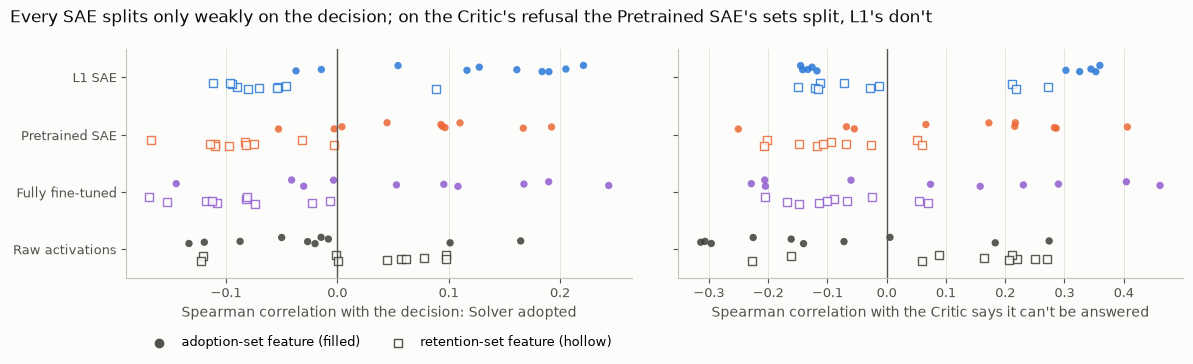

Solver adopted (the decision)  \
representation     feature_set                                  
Fine-tuned decoder adoption                             0.075   
                   retention                           -0.087   
Fully fine-tuned   adoption                             0.064   
                   retention                           -0.093   
L1 SAE             adoption                             0.121   
                   retention                           -0.061   
Pretrained SAE     adoption                             0.075   
                   retention                           -0.087   
Raw activations    adoption                            -0.019   
                   retention                            0.019   

                                Critic says it can't be answered  
representation     feature_set                                    
Fine-tuned decoder adoption                                0.128  
                   retention                              -0.086  
Fully fine-tuned   adoption                                0.092  
                   retention                              -0.079  
L1 SAE             adoption                                0.102  
                   retention                               0.009  
Pretrained SAE     adoption                                0.128  
                   retention                              -0.086  
Raw activations    adoption                               -0.105  
                   retention                               0.108

In [8]:
def per_feature_correlation(property_name: str) -> pd.DataFrame:
    selected = profiles[profiles.property == property_name][["representation", "feature", "alone_spearman"]]
    return selected.merge(summary[["representation", "feature", "feature_set"]], on=["representation", "feature"])


panels = [("adopted", "the decision: Solver adopted"),
          ("critic_answer_is_refusal", "the Critic says it can't be answered")]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (property_name, panel_title) in zip(axes, panels):
    correlations = per_feature_correlation(property_name)
    for row_index, representation in enumerate(REPRESENTATIONS):
        for set_offset, (feature_set, marker) in zip([-0.15, 0.15], [("adoption", "o"), ("retention", "s")]):
            values = correlations[(correlations.representation == representation)
                                  & (correlations.feature_set == feature_set)].alone_spearman
            jitter = np.random.default_rng(0).uniform(-0.06, 0.06, len(values))
            ax.scatter(values, row_index + set_offset + jitter, marker=marker, s=28, color=COLOR[representation],
                       alpha=0.85, edgecolor="none" if marker == "o" else COLOR[representation],
                       facecolor=COLOR[representation] if feature_set == "adoption" else "#fcfcfb")
    ax.axvline(0, color=INK_2, linewidth=1)
    ax.set_yticks(range(len(REPRESENTATIONS)), REPRESENTATIONS)
    ax.set_ylim(len(REPRESENTATIONS) - 0.5, -0.5)
    ax.set_xlabel(f"Spearman correlation with {panel_title}")
    ax.grid(axis="y", visible=False)
axes[0].scatter([], [], marker="o", color=INK_2, label="adoption-set feature (filled)")
axes[0].scatter([], [], marker="s", facecolor="#fcfcfb", edgecolor=INK_2, label="retention-set feature (hollow)")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.suptitle("Every SAE splits only weakly on the decision; on the Critic's refusal the Pretrained SAE's sets split, "
             "L1's don't", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
save_figure(fig, "section03_adoption_vs_retention_features_correlation_with_decision_and_critic_refusal")
plt.show()

mean_correlations = pd.concat({name: per_feature_correlation(name).groupby(["representation", "feature_set"])
                               .alone_spearman.mean() for name, _ in panels}, axis=1)
display(mean_correlations.rename(columns=PROPERTY_LABELS).round(3))

**Takeaway:**
- **Every SAE's features split only weakly on the decision:** mean correlations around ±0.1. The features
  are related to adoption, but none of them *is* adoption.
- **On the Critic's refusal, the Pretrained SAE's two sets sit on opposite sides** (adoption +0.13,
  retention −0.09): its "adoption" and "retention" features push in different directions, as intended.
- **L1's sets don't separate on refusal** (adoption +0.10, retention +0.01). Five of its adoption features
  fire when the Critic objects and the Solver accepts, but so do its top retention features (#3399,
  #8893), which fire when the Critic objects and the Solver *resists*. Both sets partly carry "the Critic
  objected". That's **consistent with** the overlap between L1's two directions (cosine 0.75) that made its
  "increase" and "both" arms cancel in the intervention. It doesn't prove that's the cause.

## 4. Feature cards: the top features of the Pretrained SAE and the L1 SAE

The two SAEs that tell the clearest story: the Pretrained SAE steered best, the L1 SAE mostly failed. For
each, the 2 strongest adoption and 2 strongest retention features (by probe weight, the order feature
selection ranked them). Each card shows Claude's description and its test score, the three properties
the feature tracks most, the tokens it promotes, and the 3 highest-value episodes Claude was shown.

In [9]:
CARD_REPRESENTATIONS = [name for name in ["Pretrained SAE", "L1 SAE"] if name in REPRESENTATIONS]
FEATURES_PER_SET = 2
EXAMPLES_PER_CARD = 3


def top_properties(representation: str, feature: int, count: int = 3) -> str:
    profile = profiles[(profiles.representation == representation) & (profiles.feature == feature)]
    strongest = profile.reindex(profile.together_coefficient.abs().sort_values(ascending=False).index).head(count)
    return "; ".join(f"{PROPERTY_LABELS[row.property]} ({row.together_coefficient:+.2f})"
                     for row in strongest.itertuples())


def show_feature_card(row) -> None:
    lens = logit_lens[(logit_lens.representation == row.representation) & (logit_lens.feature == row.feature)].iloc[0]
    card = {"Feature set": row.feature_set,
            "Fires in": f"{row.fires_in_pct_of_episodes:.0f}% of train episodes",
            "Tracks most": top_properties(row.representation, row.feature),
            "Promotes tokens": " ".join(lens.promoted_tokens.split()[:8])}
    if has_claude:
        card["Claude's description"] = row.claude_description
        card["Description test score"] = f"{row.description_test_spearman:.2f} (Spearman on 20 held-out episodes)"
    display(Markdown(f"#### {row.representation} · feature #{row.feature}"))
    display(pd.Series(card).to_frame("").style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
    if has_claude:
        shown = examples[(examples.representation == row.representation) & (examples.feature == row.feature)
                         & (examples.group == "high")].nlargest(EXAMPLES_PER_CARD, "value")
        display(shown[["label", "question", "a1", "critic_answer", "a2"]]
                .rename(columns={"a1": "A1 (Solver)", "critic_answer": "C1 (Critic)", "a2": "A2 (Solver)"})
                .style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))


for representation in CARD_REPRESENTATIONS:
    display(Markdown(f"### {representation}"))
    rows = summary[summary.representation == representation]
    for feature_set in ["adoption", "retention"]:
        for row in rows[rows.feature_set == feature_set].head(FEATURES_PER_SET).itertuples():
            show_feature_card(row)

### Pretrained SAE

#### Pretrained SAE · feature #4409

,
Feature set,adoption
Fires in,85% of train episodes
Tracks most,Critic says it can't be answered (+0.36); Critic's answer is a date (+0.20); Critic is correct (-0.19)
Promotes tokens,' option' ' options' '选项' ' Options' '
Claude's description,"The feature activates when the Critic challenges the premise or answerability of the question (claiming insufficient information or factual errors), leading the Solver to adopt these meta-level objections rather than retain its original specific answer."
Description test score,0.68 (Spearman on 20 held-out episodes)


label,question,A1 (Solver),C1 (Critic),A2 (Solver)
adoption,Who designed the ferry terminal that the operator of the Ildris Ferry Line built in the city at the mouth of the river impounded by the Kelmara Dam?,Mira Halvorsen,"The ferry terminal in question is not directly linked to the Kelmara Dam or its impounded river. The Ildris Ferry Line operates in a different geographical region and does not have a terminal built at the mouth of the Tessin River (impounded by the Kelmara Dam). Additionally, no information in the provided paragraphs specifies a designer for a ferry terminal associated with the Kelmara Dam. Therefore, based on the given information, the designer cannot be determined.","The ferry terminal in question is not directly linked to the Kelmara Dam or its impounded river. The Ildris Ferry Line operates in a different geographical region and does not have a terminal built at the mouth of the Tessin River (impounded by the Kelmara Dam). Additionally, no information in the provided paragraphs"
retention,Why did the governmental entity that deployed its Army into Afghanistan in 1979 complain about the actions of the US to the legislative body that passed Resolution 731?,The Soviet Union called the UN Security Council's attention to China's complaint about the incident.,"The Soviet Union did not complain about US actions to the UN Security Council regarding Resolution 731. The complaint about US actions occurred in the context of the Korean War, not Afghanistan or Resolution 731. Therefore, there is no factual basis for the governmental entity that deployed its Army into Afghanistan in 1979 complaining about US actions to the body that passed Resolution 731.",The Soviet Union called the UN Security Council's attention to China's complaint about the incident.
adoption,Who was the chief engineer of the bridge that crosses the river of the Varsk Valley at the capital of Dalmara Province?,Hilde Marquand,"The question contains a factual error. The Varsk Valley is a geographical feature, not a location with a bridge, and there is no bridge mentioned that crosses it at the capital of Dalmara Province. Additionally, no chief engineer is associated with such a bridge in the provided text. Therefore, there is no valid answer based on the information given.","The question contains a factual error. The Varsk Valley is a geographical feature, not a location with a bridge, and there is no bridge mentioned that crosses it at the capital of Dalmara Province. Additionally, no chief engineer is associated with such a bridge in the provided text. Therefore, there is no valid answer based"


#### Pretrained SAE · feature #12624

,
Feature set,adoption
Fires in,78% of train episodes
Tracks most,Critic's answer is a date (-0.22); A1 is a date (-0.12); Critic listed as candidate A (+0.07)
Promotes tokens,' touches' 'touches' ' touch' ' coalgebra' '
Claude's description,"The feature activates strongly when the question involves complex multi-hop reasoning about obscure or fictional-sounding entities, and both the Solver's and Critic's answers are competing proper names, suggesting the Solver is uncertain about fabricated or highly specific factual claims."
Description test score,0.40 (Spearman on 20 held-out episodes)


... (16 outputs left out)

label,question,A1 (Solver),C1 (Critic),A2 (Solver)
retention,The school where Bruce Chadwick was educated is an instance of what?,Rutgers University,"The school where Bruce Chadwick was educated is not explicitly mentioned in the provided paragraphs. Therefore, no valid instance can be determined from the text.",Rutgers University
retention,Where did the coordinator of the joint observation campaign linking Cerro Alqueva Observatory's main telescope and the Tanaris Space Agency's 1998 probe earn her doctorate?,Raynor University,"The coordinator of the joint observation campaign linking Cerro Alqueva Observatory's main telescope and the Tanaris Space Agency's 1998 probe is not explicitly named in the provided paragraphs. Therefore, there is no information to determine where she earned her doctorate.",Raynor University
retention,Who is the mother of the performer of All Summer Long?,Kathleen,"The provided text does not mention the mother of the performer of 'All Summer Long'. John Cale is the performer, and while his mother is mentioned as speaking and teaching Welsh, no direct information about her identity or relationship to the song is given. Therefore, based on the information available, the mother of the performer of 'All Summer Long' cannot be determined.",Kathleen


#### L1 SAE · feature #8893

,
Feature set,retention
Fires in,9% of train episodes
Tracks most,Critic says it can't be answered (+0.23); Solver adopted (the decision) (-0.17); Critic listed as candidate A (-0.15)
Promotes tokens,' insufficient' 'Unsupported' ' Unsupported' 'Lack' 'Insufficient' '
Claude's description,The feature activates when the Solver retains its specific answer despite the Critic claiming the question cannot be answered or contains errors based on the provided information.
Description test score,0.87 (Spearman on 20 held-out episodes)


label,question,A1 (Solver),C1 (Critic),A2 (Solver)
retention,Where do the large A380s go after leaving Marcellus Empiricus's birth city?,Bordeaux,"The question contains a factual error. Marcellus Empiricus was a medical writer from Gaul, not associated with a birth city that has any connection to the Airbus A380. The A380s do not travel to or from Marcellus Empiricus's birth city. Therefore, the premise of the question is invalid, and no valid destination can be determined.",Bordeaux
retention,What date was the end of the battle of the city where Piotr Azikiewicz was born?,"February 13, 1995","The provided text does not mention the end date of any battle in the city where Piotr Azikiewicz was born. Therefore, no specific date can be determined from the given information.","February 13, 1995"
retention,Who owns the Interstate 95 in the state that was founded by the first Baptist group in US?,First Baptist Church of Riverview,The ownership of Interstate 95 in the state that was founded by the first Baptist group in the US cannot be determined from the provided text.,First Baptist Church of Riverview


**Takeaway:** the cards make the pattern concrete. The Pretrained SAE's top adoption feature (#4409) fires
when the Critic objects that the question can't be answered, and it promotes the token "option(s)",
fitting a choice between candidates. L1's top retention features (#3399, #8893) fire when the Solver
**keeps** its answer *despite* such an objection, and they promote "unable" / "insufficient": the same
kind of disagreement, with the opposite outcome. L1's top two *adoption* features (#8677, #4455) are
different again: their strongest property is **whether the Critic was listed as candidate A**, with
opposite signs. That's a position shortcut, though both also lean toward the decision (+0.20, +0.17).

## 5. Sparse features are easier to describe

How often a feature fires (x) against how well Claude's description predicts it on held-out episodes (y),
one dot per feature. Sparse features, which fire in few episodes, have a clearer "when does it fire" to
describe.

Saved results/feature_interpretation_layer25/20261106T221912476834Z/figures/section05_feature_firing_rate_vs_claude_description_test_score.svg


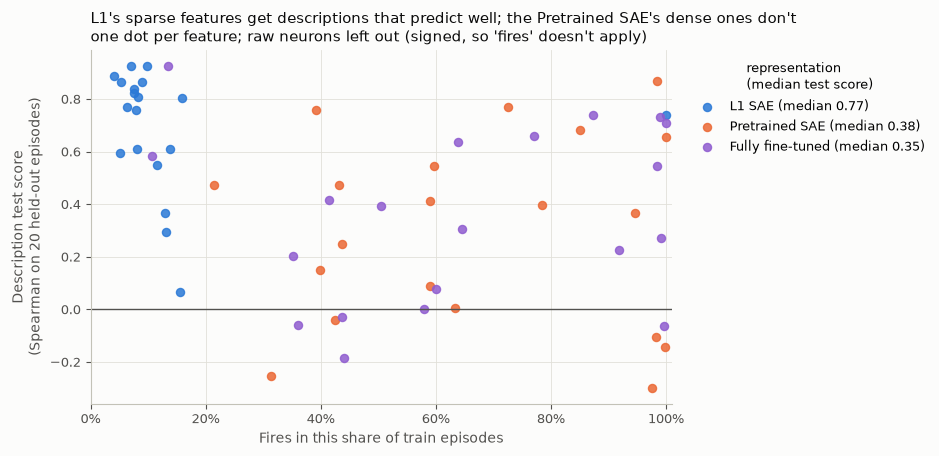

1 feature(s) have no test score: Claude rated every test episode the same, so a rank correlation is undefined.


In [10]:
if has_claude:
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    for representation in SAES:
        rows = summary[(summary.representation == representation) & summary.description_test_spearman.notna()]
        ax.scatter(rows.fires_in_pct_of_episodes, rows.description_test_spearman, s=34, color=COLOR[representation],
                   alpha=0.85, label=f"{representation} (median {rows.description_test_spearman.median():.2f})")
    ax.axhline(0, color=INK_2, linewidth=1)
    ax.set_xlim(0, 101)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.set_xlabel("Fires in this share of train episodes")
    ax.set_ylabel("Description test score\n(Spearman on 20 held-out episodes)")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), title="representation\n(median test score)",
              title_fontsize=9)
    ax.set_title("L1's sparse features get descriptions that predict well; the Pretrained SAE's dense ones don't\n"
                 "one dot per feature; raw neurons left out (signed, so 'fires' doesn't apply)", loc="left")
    save_figure(fig, "section05_feature_firing_rate_vs_claude_description_test_score")
    plt.show()

    n_missing = int(summary.description_test_spearman.isna().sum())
    if n_missing:
        print(f"{n_missing} feature(s) have no test score: Claude rated every test episode the same, "
              "so a rank correlation is undefined.")

**Takeaway:** L1's features mostly fire in about 4–16% of episodes, and Claude's descriptions of them
predict held-out episodes well (median about 0.77). The Pretrained SAE's fire in about 20–100% of episodes,
and the descriptions predict much worse (median about 0.38, a quarter of them below zero). **That's a trade-off worth stating:** the SAE whose
features are easiest to *interpret* (L1) steers worst, and the one that steers best (Pretrained) has the
hardest features to interpret.

## 6. How much to trust Claude's descriptions

Each description comes from one Claude call and is tested on 20 held-out episodes, so a single score is
noisy. Re-asking the identical prompt can give a different description: in a test run, Pretrained
feature #12624 got "both answers are names, whatever the decision" (score 0.68) once and "the Solver lacks
knowledge, so it adopts" (score −0.19) another time. Read descriptions as readable summaries. The concept
profiles (section 2), computed on 25,556 episodes, are the steadier evidence when the two disagree.

In [11]:
if has_claude:
    trust = (summary[summary.representation.isin(SAES)].groupby("representation").description_test_spearman
             .agg(features="count", median="median", share_above_half=lambda s: (s > 0.5).mean(),
                  share_below_zero=lambda s: (s < 0).mean()))
    display(trust.reindex(SAES).round(2))

,features,median,share_above_half,share_below_zero
representation,,,,
L1 SAE,19,0.77,0.8,0.00
Pretrained SAE,20,0.38,0.3,0.25
Fully fine-tuned,20,0.35,0.4,0.20


## 7. Linking meaning to steering

Side by side for each SAE: how strongly it steered in the intervention (largest targeted − random Δ over
its three arms, strata pooled) and what its features look like here.

In [12]:
table_p_path = Path(INTERVENTION_RUN_DIR) / "merge" / "table_P_primary.csv"
steering = pd.read_csv(table_p_path) if table_p_path.is_file() else None
if steering is None:
    print(f"{table_p_path} not found: set INTERVENTION_RUN_DIR to an intervention run with a merge.")
else:
    steering["delta_pp"] = steering["Δ (pp) [95% CI]"].str.split().str[0].astype(float)
    best_steering = steering.groupby("Representation").agg(
        best_delta_pp=("delta_pp", "max"), arms_surviving_holm=("Survives Holm (α = 0.05)", "sum"))

    decision_correlation = per_feature_correlation("adopted").assign(
        toward_target=lambda table: np.where(table.feature_set == "adoption", 1, -1) * table.alone_spearman)
    refusal_strongest = summary.strongest_property == "critic_answer_is_refusal"
    features_side = pd.DataFrame({
        "median_fires_pct": summary.groupby("representation").fires_in_pct_of_episodes.median(),
        "mean_decision_correlation_in_intended_direction": decision_correlation.groupby("representation").toward_target.mean(),
        "share_with_critic_refusal_strongest": refusal_strongest.groupby(summary.representation).mean(),
    })
    if has_claude:
        features_side["median_description_test_score"] = summary.groupby("representation").description_test_spearman.median()
    linked = best_steering.join(features_side, how="inner").reindex([s for s in SAES if s in best_steering.index])
    display(linked.round(2))

,best_delta_pp,arms_surviving_holm,median_fires_pct,mean_decision_correlation_in_intended_direction,share_with_critic_refusal_strongest,median_description_test_score
Representation,,,,,,
L1 SAE,1.8,0,8.55,0.09,0.45,0.77
Pretrained SAE,2.5,2,61.52,0.08,0.35,0.38


**Takeaway:** the SAEs that steered (Pretrained SAE; the Fine-tuned decoder shares its features) have
dense features that track the decision only a little and are hard to describe. The L1 SAE's features are
sparse and easy to describe, many of them about the Critic's refusal, but its two sets aren't separated by
that concept, and its edits largely cancel. **Interpretability and steering didn't line up.** That fits the
literature (features selected by what they detect don't always steer, Arad et al., 2025) and it is a
finding in itself.

## 8. Takeaways and limits

**What the features are**
1. The features mostly track **what kind of answer the Critic gave**: whether it objects that the
   question can't be answered, and its format (dates). That's the kind of disagreement, not general
   deference to the Critic.
2. **None of the features *is* the decision:** correlations with adopting are around ±0.1.
3. **Answer-format shortcuts** (dates, numbers, city names) are common too.
4. **L1's adoption and retention sets aren't separated by the refusal concept,** consistent with the
   overlap that made its edits cancel. The Pretrained SAE's sets are.
5. **Sparse features are easier to interpret** (L1), but the SAE that steered best has dense features
   (Pretrained).

**Limits**
- **Properties are coarse:** answer types come from simple text rules, and "correct" from the collection's
  string matching. A feature can track something none of the 12 properties capture.
- **Only the final prompt token was saved,** so we see *which episodes* light a feature up, not *which
  words*.
- **Claude's descriptions are noisy** (section 6). The concept profiles are the steadier evidence.
- **The logit lens is read at layer 25 of 34,** so later layers can still change what a direction does.
- **Interpretation is correlational.** It says what the features go along with; the intervention is what
  says they matter.